In [309]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

%matplotlib inline
np.random.seed(42)

In [310]:
data = pd.read_csv(f'bioresponse.csv')
data

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3746,1,0.033300,0.506409,0.10,0.0,0.209887,0.633426,0.297659,0.376124,0.727093,...,0,0,0,0,0,0,0,0,0,0
3747,1,0.133333,0.651023,0.15,0.0,0.151154,0.766505,0.170876,0.404546,0.787935,...,0,0,1,0,1,0,1,0,0,0
3748,0,0.200000,0.520564,0.00,0.0,0.179949,0.768785,0.177341,0.471179,0.872241,...,0,0,0,0,0,0,0,0,0,0
3749,1,0.100000,0.765646,0.00,0.0,0.536954,0.634936,0.342713,0.447162,0.672689,...,0,0,0,0,0,0,0,0,0,0


In [311]:
data.shape

(3751, 1777)

In [312]:
# загрузка и подготовка данных
df = pd.read_csv('bioresponse.csv')
print(df.shape)

# первая колонка — целевая переменная
y = df.iloc[:, 0].values.reshape(1, -1)
X = df.iloc[:, 1:].values.T          # shape (1776, N)

# нормализация (в описании сказано, что уже нормированы, но подстрахуемся)
X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 1e-8)

# 75% train / 25% test
X_train, X_test, y_train, y_test = train_test_split(
    X.T, y.T, test_size=0.25, random_state=42, stratify=y.T
)
X_train, X_test = X_train.T, X_test.T
y_train, y_test = y_train.T, y_test.T

print("train:", X_train.shape, " test:", X_test.shape)

(3751, 1777)
train: (1776, 2813)  test: (1776, 938)


In [313]:
def sigmoid(z):
    """
    Compute the sigmoid of z

    Arguments:
    z -- A scalar or numpy array of any size.

    Return:
    s -- sigmoid(z)
    """
    s = 1./(1.+np.exp(-z))

    return s

In [314]:
def initialize_with_zeros(dim):
    """
    This function creates a vector of zeros of shape (dim, 1) for w and initializes b to 0.

    Argument:
    dim -- size of the w vector we want (or number of parameters in this case)

    Returns:
    w -- initialized vector of shape (dim, 1)
    b -- initialized scalar (corresponds to the bias)
    """
    #w = np.ones((dim,1))
    w = np.random.normal(loc=0.0, scale=0.01, size=dim).reshape(dim,1)
    b = 0.

    return w, b

In [315]:
def propagate(w, b, X, Y):
    """
    Implement the cost function and its gradient for the propagation explained above

    Arguments:
    w -- weights, a numpy array of size which equals the number of features
    b -- bias, a scalar
    X -- data
    Y -- true "label" vector (containing 0 and 1) of size (1, number of examples)

    Return:
    cost -- negative log-likelihood cost for logistic regression
    dw -- gradient of the loss with respect to w, thus same shape as w
    db -- gradient of the loss with respect to b, thus same shape as b

    """
    m = X.shape[1]
    #print('number of objects = ',len(X))

    # FORWARD PROPAGATION (FROM X TO COST)
    A = sigmoid(np.dot(w.T,X)+b )                                 # compute activation
    cost = -(1./m) * np.sum(Y*np.log(A + 1e-15) + (1-Y)*np.log(1-A + 1e-15))   # compute cost

    # BACKWARD PROPAGATION (TO FIND GRAD)
    dw = (1./m)*np.dot(X,(A-Y).T)
    db = (1./m)*np.sum(A-Y,axis=1)

    grads = {"dw": dw,
             "db": db}

    return grads, cost

In [316]:
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    """
    This function optimizes w and b by running a gradient descent algorithm

    Arguments:
    w -- weights, a numpy array
    b -- bias, a scalar
    X -- data
    Y -- true "label" vector (containing 0 and 1), of shape (1, number of examples)
    num_iterations -- number of iterations of the optimization loop
    learning_rate -- learning rate of the gradient descent update rule
    print_cost -- True to print the loss every 100 steps

    Returns:
    params -- dictionary containing the weights w and bias b
    grads -- dictionary containing the gradients of the weights and bias with respect to the cost function
    costs -- list of all the costs computed during the optimization, this will be used to plot the learning curve.

    """

    costs = []

    for i in range(num_iterations):

        # Cost and gradient calculation
        grads, cost = propagate(w,b,X,Y)

        # Retrieve derivatives from grads
        dw = grads["dw"]
        db = grads["db"]

        # update rule
        w -=learning_rate * dw
        b -=learning_rate * db

        # Record the costs => learning curve
        if i % 100 == 0:
            costs.append(cost)

        # Print the cost every 100 training iterations
        if print_cost and i // 100 == 0:
            print (f"Cost after iteration {i}: {round(cost[0], 7)}")

    params = {"w": w,
              "b": b}

    grads = {"dw": dw,
             "db": db}

    return params, grads, costs

In [317]:
def predict(w, b, X, threshold = 0.5):
    '''
    Predict whether the label is 0 or 1 using learned logistic regression parameters (w, b)

    Arguments:
    w -- weights, a numpy array
    b -- bias, a scalar
    X -- data

    Returns:
    Y_prediction -- a numpy array (vector) containing all predictions (0/1) for the examples in X
    '''

    m = X.shape[1] # - number of objects
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1) # X.shape[0] - number of features

    # Compute vector "A" predicting the probabilities
    A = sigmoid(np.dot(w.T,X)+b)

    for i in range(A.shape[1]):

        # Convert probabilities A[0,i] to actual predictions p[0,i]
        if (A[0,i]<=threshold):
            Y_prediction[0][i]=0
        else:
            Y_prediction[0][i]=1

    return Y_prediction #Дальше надо переписывать функцию под GD и т.д.

In [318]:
def accuracy(w, b, X, Y):
    return np.mean(predict(w, b, X) == Y) * 100

In [319]:
def optimize_gd(w, b, X, Y, num_iterations, learning_rate, print_cost=False):
    costs = []
    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]
        w -= learning_rate * dw
        b -= learning_rate * db
        if i % 100 == 0:
            costs.append(cost)
        if print_cost and i % 1000 == 0:
            print('GD iter - ', i, 'cost = ', cost)
    return {"w": w, "b": b}, costs

In [320]:
w, b = initialize_with_zeros(X_train.shape[0])
params_gd, costs_gd = optimize_gd(w, b, X_train, y_train,
                                  num_iterations=2000,
                                  learning_rate=0.05,
                                  print_cost=True)

acc_gd = accuracy(params_gd["w"], params_gd["b"], X_test, y_test)
print('GD test accuracy =', acc_gd)

GD iter -  0 cost =  0.7071623435073111
GD iter -  1000 cost =  0.24789653141683687
GD test accuracy = 75.5863539445629


In [321]:
def optimize_sgd(w, b, X, Y, num_epochs, learning_rate,
                 batch_size, print_cost=False):
    """
    SGD / mini-batch GD.
    num_epochs — число проходов по всему датасету.
    Один "iteration" здесь = один мини-батч.
    """
    costs = []
    m = X.shape[1]
    n_batches = int(np.ceil(m / batch_size))
    iteration = 0

    for epoch in range(num_epochs):
        perm = np.random.permutation(m)
        X_shuffled = X[:, perm]
        Y_shuffled = Y[:, perm]

        for k in range(n_batches):
            start = k * batch_size
            end = min(start + batch_size, m)
            X_batch = X_shuffled[:, start:end]
            Y_batch = Y_shuffled[:, start:end]

            grads, cost = propagate(w, b, X_batch, Y_batch)
            w -= learning_rate * grads["dw"]
            b -= learning_rate * grads["db"]

            if iteration % 100 == 0:
                _, full_cost = propagate(w, b, X, Y)
                costs.append(full_cost)
            iteration += 1

        if print_cost:
            _, full_cost = propagate(w, b, X, Y)
            print('SGD epoch -', epoch, 'full cost =', full_cost)

    return {"w": w, "b": b}, costs

In [322]:
w, b = initialize_with_zeros(X_train.shape[0])
params_sgd, costs_sgd = optimize_sgd(w, b, X_train, y_train,
                                     num_epochs=20,
                                     learning_rate=0.001,
                                     batch_size=32,
                                     print_cost=True)

acc_sgd = accuracy(params_sgd["w"], params_sgd["b"], X_test, y_test)
print('SGD test accuracy -', acc_sgd)

SGD epoch - 0 full cost = 0.6249517401138411
SGD epoch - 1 full cost = 0.5848415223222891
SGD epoch - 2 full cost = 0.5587713121092444
SGD epoch - 3 full cost = 0.5395028886699721
SGD epoch - 4 full cost = 0.5243135571126855
SGD epoch - 5 full cost = 0.5117060320801626
SGD epoch - 6 full cost = 0.5011443346206158
SGD epoch - 7 full cost = 0.4918289863367269
SGD epoch - 8 full cost = 0.48390298766143836
SGD epoch - 9 full cost = 0.476896424867505
SGD epoch - 10 full cost = 0.4702290892569305
SGD epoch - 11 full cost = 0.46443429702193006
SGD epoch - 12 full cost = 0.4590901508214771
SGD epoch - 13 full cost = 0.4542338819333913
SGD epoch - 14 full cost = 0.4496773443588777
SGD epoch - 15 full cost = 0.44554412869607135
SGD epoch - 16 full cost = 0.4421481109167644
SGD epoch - 17 full cost = 0.437844998125171
SGD epoch - 18 full cost = 0.43473074586282745
SGD epoch - 19 full cost = 0.4311700110629939
SGD test accuracy - 75.79957356076758


In [323]:
def optimize_adam(w, b, X, Y, num_iterations, learning_rate,
                  beta1=0.9, beta2=0.999, epsilon=1e-8,
                  batch_size=None, print_cost=False):
    """
    Adam. Если batch_size=None — full-batch (как GD),
    иначе — mini-batch Adam.
    """
    costs = []
    m = X.shape[1]
    v_dw, v_db = np.zeros_like(w), 0.
    s_dw, s_db = np.zeros_like(w), 0.
    t = 0

    if batch_size is None:
        batch_size = m
    n_batches = int(np.ceil(m / batch_size))

    for it in range(num_iterations):
        if it % n_batches == 0:
            perm = np.random.permutation(m)
            X_sh = X[:, perm]
            Y_sh = Y[:, perm]
        k = it % n_batches
        X_batch = X_sh[:, k*batch_size:(k+1)*batch_size]
        Y_batch = Y_sh[:, k*batch_size:(k+1)*batch_size]

        grads, _ = propagate(w, b, X_batch, Y_batch)
        dw, db = grads["dw"], grads["db"]

        t += 1
        #Моменты ADAM
        v_dw = beta1 * v_dw + (1 - beta1) * dw
        v_db = beta1 * v_db + (1 - beta1) * db
        s_dw = beta2 * s_dw + (1 - beta2) * (dw ** 2)
        s_db = beta2 * s_db + (1 - beta2) * (db ** 2)

        #Байесовское смещение
        v_dw_c = v_dw / (1 - beta1 ** t)
        v_db_c = v_db / (1 - beta1 ** t)
        s_dw_c = s_dw / (1 - beta2 ** t)
        s_db_c = s_db / (1 - beta2 ** t)

        w -= learning_rate * v_dw_c / (np.sqrt(s_dw_c) + epsilon)
        b -= learning_rate * v_db_c / (np.sqrt(s_db_c) + epsilon)

        if it % 100 == 0:
            _, full_cost = propagate(w, b, X, Y)
            costs.append(full_cost)
        if print_cost and it % 1000 == 0:
            _, full_cost = propagate(w, b, X, Y)
            print('Adam iter ', it, 'cost = ', full_cost)

    return {"w": w, "b": b}, costs

In [ ]:
w, b = initialize_with_zeros(X_train.shape[0])
params_adam, costs_adam = optimize_adam(w, b, X_train, y_train,
                                        num_iterations=2000,
                                        learning_rate=0.001,
                                        batch_size=32,
                                        print_cost=True)

acc_adam = accuracy(params_adam["w"], params_adam["b"], X_test, y_test)
print('Adam test accuracy = ', acc_adam) #Все три одинаковы по точности???

Adam iter  0 cost =  0.7060682038549958
Adam iter  1000 cost =  0.30910287154254
Adam test accuracy =  76.22601279317696


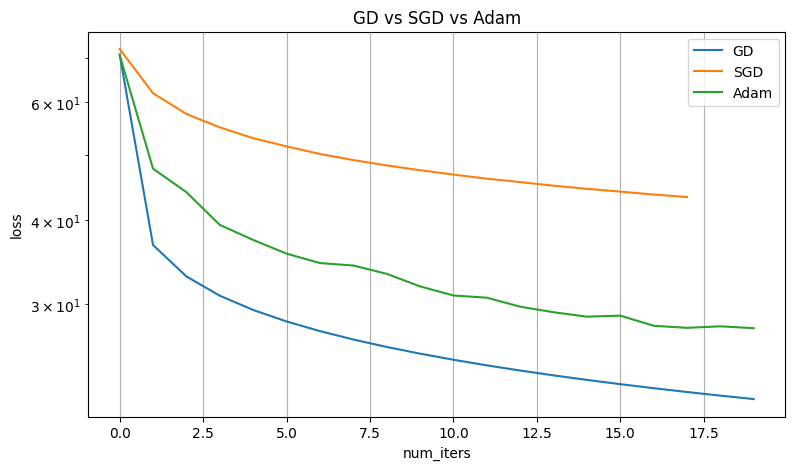

In [325]:
plt.figure(figsize=(9, 5))
plt.plot(np.array(costs_gd) * 100, label="GD")
plt.plot(np.array(costs_sgd) * 100, label="SGD")
plt.plot(np.array(costs_adam) * 100, label="Adam")
plt.xlabel("num_iters")
plt.ylabel("loss")
plt.title("GD vs SGD vs Adam")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.show()

C:\Users\popov_n_m\AppData\Local\Temp\ipykernel_2944\4247852194.py:11: RuntimeWarning: overflow encountered in exp
  s = 1./(1.+np.exp(-z))


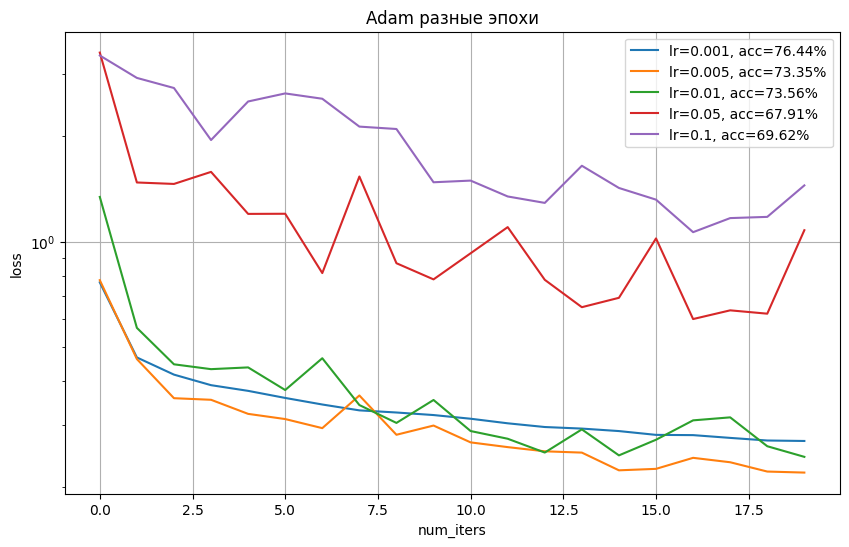

lr=0.001    test accuracy = 76.44%
lr=0.005    test accuracy = 73.35%
lr=0.01     test accuracy = 73.56%
lr=0.05     test accuracy = 67.91%
lr=0.1      test accuracy = 69.62%


In [326]:
learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]
results = {}

plt.figure(figsize=(10, 6))
for lr in learning_rates:
    w, b = initialize_with_zeros(X_train.shape[0])
    params, costs = optimize_adam(w, b, X_train, y_train,
                                  num_iterations=2000,
                                  learning_rate=lr,
                                  batch_size=32)
    acc = accuracy(params["w"], params["b"], X_test, y_test)
    results[lr] = acc
    plt.plot(np.array(costs), label=f"lr={lr}, acc={acc:.2f}%")

plt.xlabel("num_iters")
plt.ylabel("loss")
plt.title("Adam разные эпохи")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.show()

for lr, acc in results.items():
    print(f"lr={lr:<6}   test accuracy = {acc:.2f}%")
# При большом lr прыгает Loss, есть осцилляция(хорошее слово выучил)
# В данном случае при меньшем lr осцилляция меньше и Loss тоже

# Вывод
## Сначала я испугался, т.к. увидел везде accuracy 75%, подумал, что что-то сделал не так. Почитал, понял, что Логистическая регрессия не очень сюда подходит и такая точность нормальная, а раз она одинаковая, то значит все три метода сошлись к локальному минимуму, погрешность в долях процентов - шум.
## GD - Стабильнее всего по Loss, но требует много итерация проходит через все объекты(2800 против SGD и Adam с batch_size = 32)
## SGD - Быстрее в разы, т.к. использует batch
## ADAM - Самый быстрый и устойчивый, менее чувствителен к выбору lr

## ADAM для меня самый лучший, сам его использовал для обучения сверточной нейросети к диплому(я только начинаю разбираться в этом и уже читал где-то, что он не очень подходит для CNN), только почему ADAM лучшую точность показал на lr = 0.001, ведь это слишком медленно и он не должен успевать сходиться???